In [7]:
df = pd.read_csv('data/dataset.csv')
df.head()

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  str    
 2   artists           113999 non-null  str    
 3   album_name        113999 non-null  str    
 4   track_name        113999 non-null  str    
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          114000 non-nu

In [10]:
df.shape

(114000, 21)

In [11]:
df.columns

Index(['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name',
       'popularity', 'duration_ms', 'explicit', 'danceability', 'energy',
       'key', 'loudness', 'mode', 'speechiness', 'acousticness',
       'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature',
       'track_genre'],
      dtype='str')

In [12]:
df.isnull().sum()

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df.isnull().sum()

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [15]:
df[df["track_name"].isnull()]

,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,...,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


In [16]:
df = df.dropna(subset=["artists","album_name","track_name"])

In [17]:
df.shape

(113999, 21)

In [19]:
df = df.drop(columns=["Unnamed: 0"])

In [20]:
df.shape

(113999, 20)

In [21]:
genre_pop = df.groupby('track_genre')["popularity"].mean()

In [22]:
genre_pop.sort_values(ascending=False).head(10)

track_genre
pop-film     59.283000
k-pop        56.952953
chill        53.651000
sad          52.379000
grunge       49.594000
indian       49.539000
anime        48.772000
emo          48.128000
sertanejo    47.866000
pop          47.576000
Name: popularity, dtype: float64

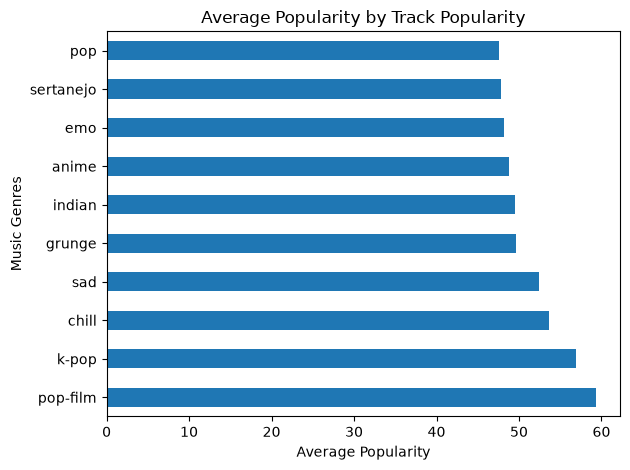

In [26]:
import matplotlib.pyplot as plt

genre_pop.sort_values(ascending=False).head(10).plot(
    kind = "barh",
    title = "Average Popularity by Track Popularity",
    xlabel = "Average Popularity",
    ylabel = "Music Genres"
)

plt.tight_layout()
plt.show()

In [28]:
genre_dance = df.groupby("track_genre")["danceability"].mean()
genre_dance.sort_values(ascending=False).head(10)

track_genre
kids              0.778906
chicago-house     0.766176
reggaeton         0.758521
latino            0.757057
reggae            0.745331
hip-hop           0.736154
dancehall         0.734169
minimal-techno    0.729395
detroit-techno    0.722568
latin             0.721902
Name: danceability, dtype: float64

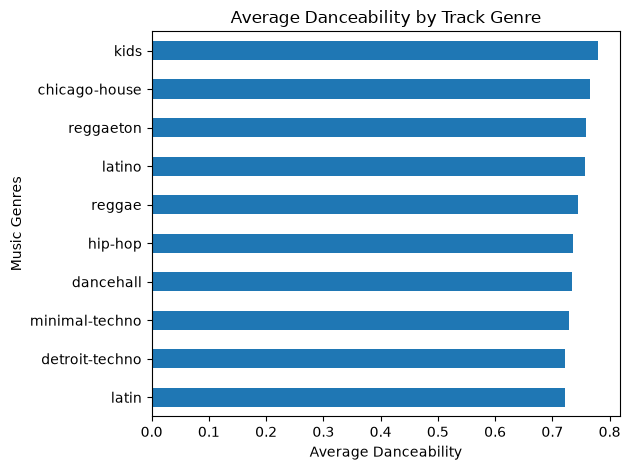

In [30]:
top_10_dance = genre_dance.sort_values(ascending=False).head(10)

top_10_dance.sort_values().plot(
    kind = "barh",
    title = "Average Danceability by Track Genre",
    xlabel = "Average Danceability",
    ylabel = "Music Genres"
)
plt.tight_layout()
plt.show()

In [31]:
df["energy"].corr(df["popularity"])

np.float64(0.0010531126538156767)

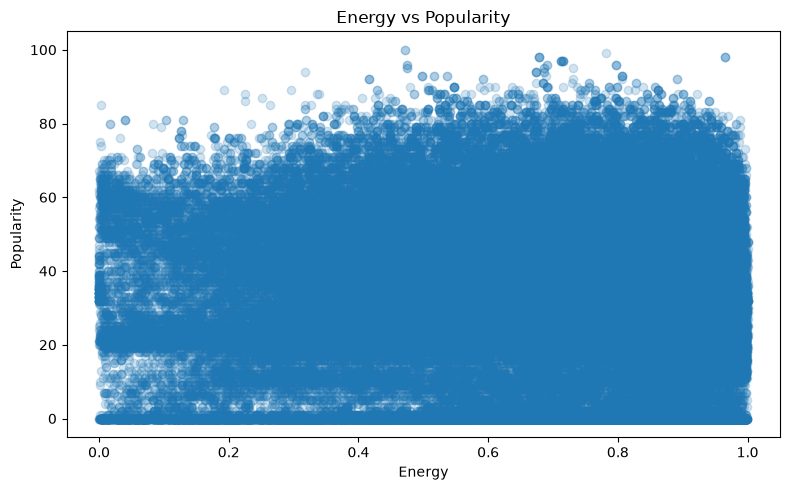

In [32]:
plt.figure(figsize=(8,5))

plt.scatter(df["energy"], df["popularity"], alpha=0.2)

plt.title("Energy vs Popularity")
plt.xlabel("Energy")
plt.ylabel("Popularity")

plt.tight_layout()
plt.show()






In [34]:
df.groupby("track_genre")["danceability"].mean()

track_genre
acoustic       0.549593
afrobeat       0.669580
alt-rock       0.534493
alternative    0.559927
ambient        0.367867
                 ...   
techno         0.684348
trance         0.583409
trip-hop       0.634695
turkish        0.616077
world-music    0.414572
Name: danceability, Length: 114, dtype: float64

In [38]:
df.groupby("track_genre")["energy"].mean()


track_genre
acoustic       0.435368
afrobeat       0.702812
alt-rock       0.754173
alternative    0.720030
ambient        0.237162
                 ...   
techno         0.746413
trance         0.845272
trip-hop       0.622363
turkish        0.609804
world-music    0.532987
Name: energy, Length: 114, dtype: float64

In [39]:
genre_energy = df.groupby("track_genre")["energy"].mean()

genre_energy.sort_values(ascending=False).head(10)

track_genre
death-metal      0.931470
grindcore        0.924201
metalcore        0.914485
happy            0.910971
hardstyle        0.901246
drum-and-bass    0.876635
black-metal      0.874897
heavy-metal      0.874003
party            0.871237
j-idol           0.868677
Name: energy, dtype: float64

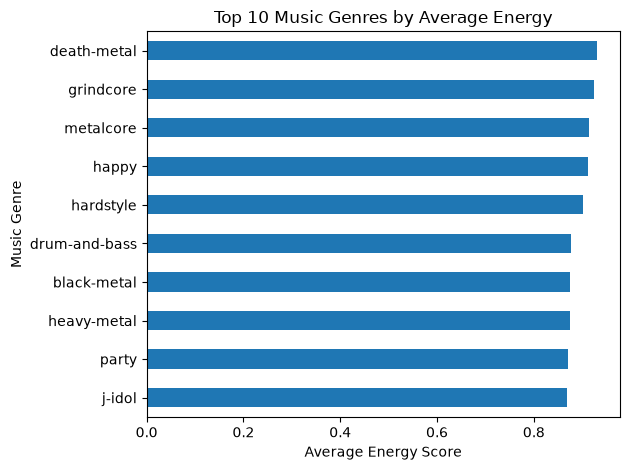

In [40]:
top_10_energy = genre_energy.sort_values(ascending=False).head(10)

top_10_energy.sort_values().plot(
    kind="barh",
    title="Top 10 Music Genres by Average Energy",
    xlabel="Average Energy Score",
    ylabel="Music Genre"
)

plt.tight_layout()
plt.show()

In [44]:
genre_tempo = df.groupby("track_genre")["tempo"].mean()

In [45]:
genre_tempo.sort_values(ascending=False).head(10)

track_genre
drum-and-bass    155.241712
happy            152.908962
hardstyle        146.837452
forro            140.362197
j-idol           136.112004
power-pop        134.651615
dubstep          133.631709
punk             133.600518
trance           133.276726
breakbeat        133.030213
Name: tempo, dtype: float64

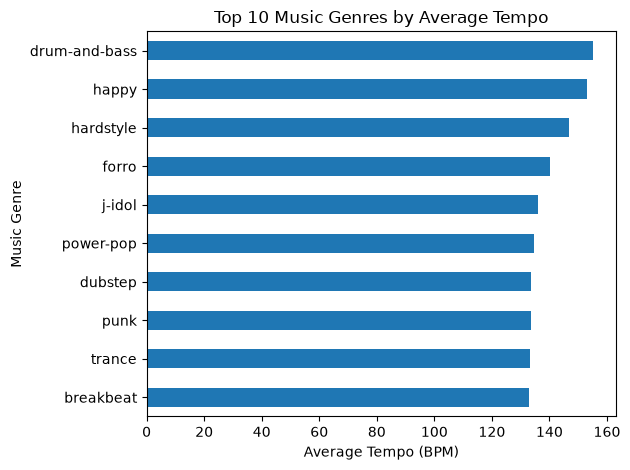

In [46]:
top_10_tempo = genre_tempo.sort_values(ascending=False).head(10)

top_10_tempo.sort_values().plot(
    kind="barh",
    title="Top 10 Music Genres by Average Tempo",
    xlabel="Average Tempo (BPM)",
    ylabel="Music Genre"
)

plt.tight_layout()
plt.show()

In [47]:
audio_features = [
    "danceability",
    "energy",
    "loudness",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo"
]

correlation_matrix = df[audio_features].corr()

correlation_matrix

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
danceability,1.000000,0.134325,0.259076,0.108625,-0.171531,-0.185608,-0.131620,0.477347,-0.050448
energy,0.134325,1.000000,0.761690,0.142508,-0.733908,-0.181880,0.184795,0.258937,0.247852
loudness,0.259076,0.761690,1.000000,0.060826,-0.589804,-0.433478,0.076897,0.279851,0.212447
speechiness,0.108625,0.142508,0.060826,1.000000,-0.002184,-0.089617,0.205218,0.036637,0.017274
acousticness,-0.171531,-0.733908,-0.589804,-0.002184,1.000000,0.104033,-0.020693,-0.107081,-0.208231
instrumentalness,-0.185608,-0.181880,-0.433478,-0.089617,0.104033,1.000000,-0.079896,-0.324310,-0.050328
liveness,-0.131620,0.184795,0.076897,0.205218,-0.020693,-0.079896,1.000000,0.019093,0.000603
valence,0.477347,0.258937,0.279851,0.036637,-0.107081,-0.324310,0.019093,1.000000,0.078269
tempo,-0.050448,0.247852,0.212447,0.017274,-0.208231,-0.050328,0.000603,0.078269,1.000000


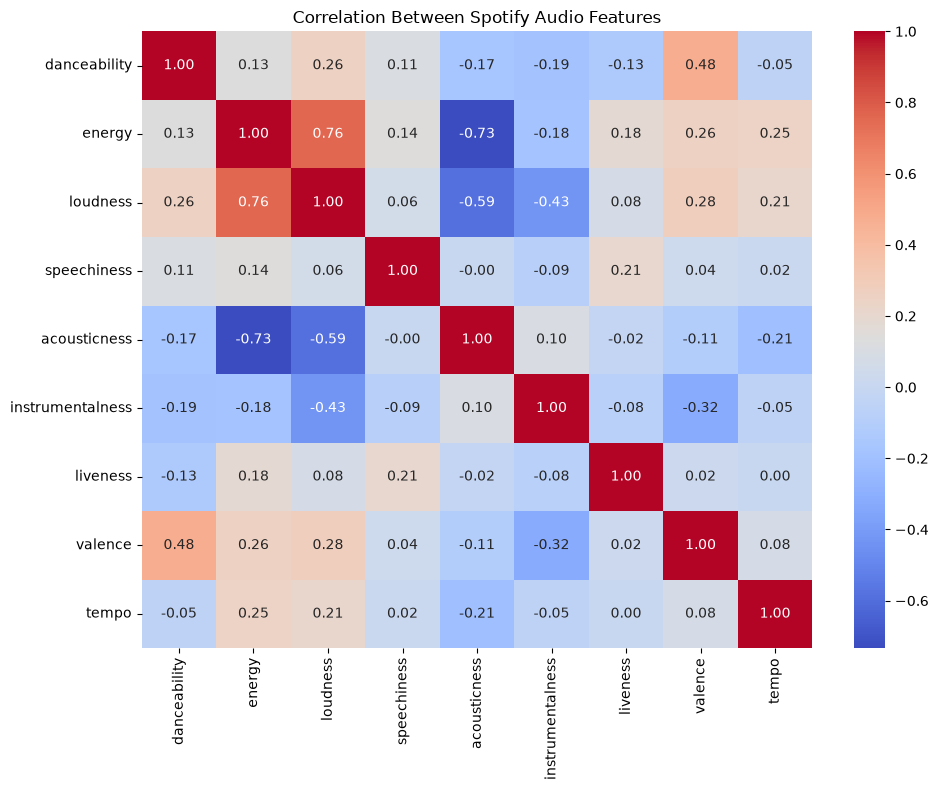

In [48]:
import seaborn as sns

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Spotify Audio Features")
plt.tight_layout()
plt.show()

In [49]:
artist_popularity = df.groupby("artists")["popularity"].mean()

In [50]:
artist_popularity.sort_values(ascending=False).head(10)

artists
Sam Smith;Kim Petras           100.0
Bizarrap;Quevedo                99.0
Manuel Turizo                   98.0
Bad Bunny;Chencho Corleone      97.0
Bad Bunny;Bomba Estéreo         94.5
Joji                            94.0
Beyoncé                         93.0
Harry Styles                    92.0
Rema;Selena Gomez               92.0
Rauw Alejandro;Lyanno;Brray     91.0
Name: popularity, dtype: float64

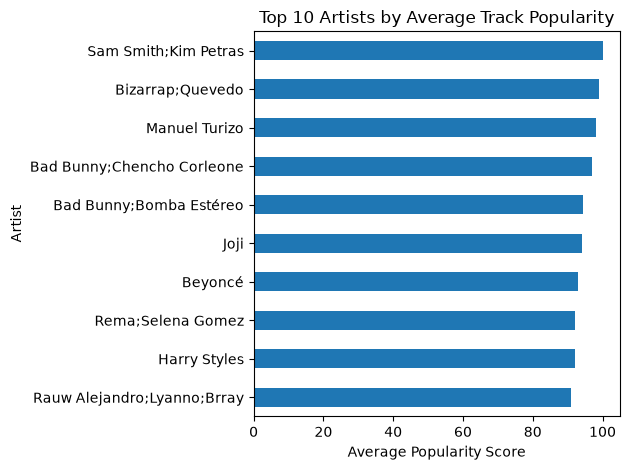

In [51]:
top_10_artists = artist_popularity.sort_values(ascending=False).head(10)

top_10_artists.sort_values().plot(
    kind="barh",
    title="Top 10 Artists by Average Track Popularity",
    xlabel="Average Popularity Score",
    ylabel="Artist"
)

plt.tight_layout()
plt.show()

In [52]:
artist_track_counts = df.groupby("artists")["track_name"].count()

artist_track_counts.sort_values(ascending=False).head(10)

artists
The Beatles        279
George Jones       271
Stevie Wonder      236
Linkin Park        224
Ella Fitzgerald    222
Prateek Kuhad      217
Feid               202
Chuck Berry        190
Håkan Hellström    183
OneRepublic        181
Name: track_name, dtype: int64

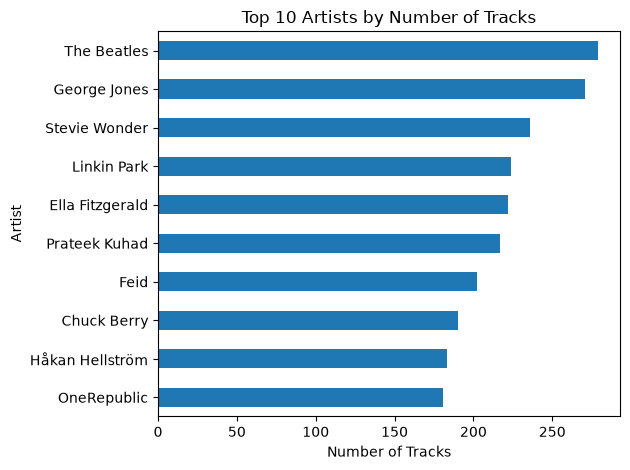

In [53]:
top_10_artist_counts = artist_track_counts.sort_values(
    ascending=False
).head(10)

top_10_artist_counts.sort_values().plot(
    kind="barh",
    title="Top 10 Artists by Number of Tracks",
    xlabel="Number of Tracks",
    ylabel="Artist"
)

plt.tight_layout()
plt.show()

In [54]:
df["duration_min"] = df["duration_ms"] / 60000

df["duration_min"].describe()

count    113999.000000
mean          3.800519
std           1.788268
min           0.143100
25%           2.901100
50%           3.548433
75%           4.358433
max          87.288250
Name: duration_min, dtype: float64

In [56]:
genre_duration = df.groupby("track_genre")["duration_min"].mean()

genre_duration.sort_values(ascending=False).head(10)

track_genre
detroit-techno    6.200207
minimal-techno    6.147721
chicago-house     6.114231
breakbeat         5.362704
iranian           5.328492
gospel            5.220301
techno            5.205191
black-metal       5.185052
new-age           4.984511
world-music       4.953260
Name: duration_min, dtype: float64

In [57]:
genre_duration.sort_values(ascending=True).head(10)

track_genre
grindcore      2.229225
children       2.316463
study          2.359476
sad            2.563348
disney         2.604289
kids           2.611551
honky-tonk     2.705465
chill          2.816833
rockabilly     2.873978
rock-n-roll    2.894889
Name: duration_min, dtype: float64

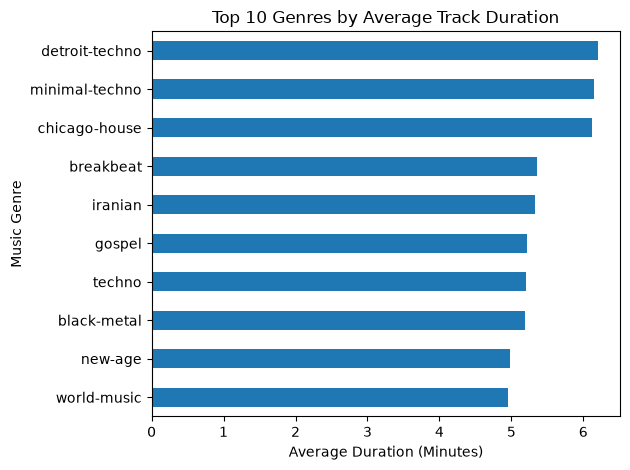

In [58]:
top_10_duration = genre_duration.sort_values(
    ascending=False
).head(10)

top_10_duration.sort_values().plot(
    kind="barh",
    title="Top 10 Genres by Average Track Duration",
    xlabel="Average Duration (Minutes)",
    ylabel="Music Genre"
)

plt.tight_layout()
plt.show()

In [59]:
df.groupby("explicit")["popularity"].mean()

explicit
False    32.938207
True     36.454191
Name: popularity, dtype: float64

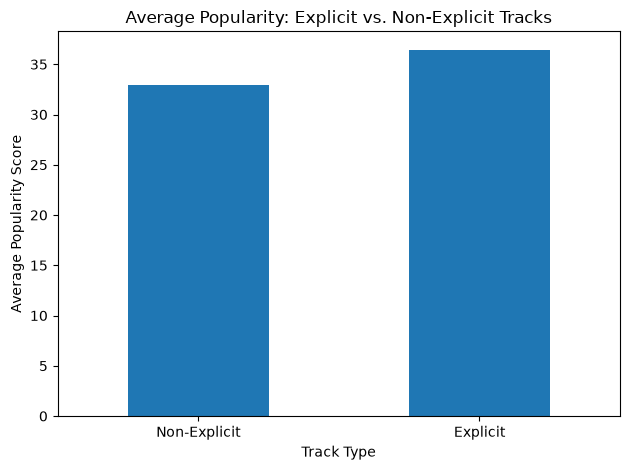

In [60]:
explicit_popularity = df.groupby("explicit")["popularity"].mean()

explicit_popularity.index = [
    "Non-Explicit",
    "Explicit"
]

explicit_popularity.plot(
    kind="bar",
    title="Average Popularity: Explicit vs. Non-Explicit Tracks",
    xlabel="Track Type",
    ylabel="Average Popularity Score",
    rot=0
)

plt.tight_layout()
plt.show()